<img src="https://porvir-5g-project.github.io/unisinos.png" alt="Unisinos" width="200" align="right">

# Trabalho 02 — Deep Learning (PPGCA/Unisinos, 2026/2)
## Adivinha o Desenho: uma rede neural que reconhece rabiscos (Quick, Draw!)

Autor: Epitácio Vicente do Nascimento Neto · Disciplina: Deep Learning · Prof. Dr. Felipe André Zeiser

**O problema.** Em segundos, uma pessoa desenha um gato, uma casa ou um sol, e o computador precisa dizer o que é. Esse tipo de reconhecimento de rabiscos aparece em telas de toque, jogos, acessibilidade e busca por esboço. Os dados vêm do **Quick, Draw!** (Google Creative Lab, licença CC BY 4.0): milhões de desenhos feitos por pessoas reais, guardados como imagens de 28×28 pixels.

**O que será feito.** Um subconjunto de **18 categorias** (gato, cachorro, círculo, sol, bola de basquete, casa, castelo, maçã, árvore, flor, carro, bicicleta, peixe, pássaro, relógio, estrela, guarda-chuva, avião), algumas parecidas de propósito, para responder cinco perguntas simples.

**Roteiro**

| Seção | Pergunta |
|---|---|
| 1 | Os dados: como são os rabiscos? |
| 2 | Uma rede com "olhos" (CNN) reconhece melhor que uma rede comum (MLP) e que uma conta simples (regressão logística)? |
| 3 | Que categorias a rede confunde, e por quê? |
| 4 | Quantos desenhos de treino são necessários? |
| 5 | A rede aguenta desenhos fora do padrão (deslocados, girados, pequenos, de traço grosso)? |
| 6 | A confiança que a rede declara é confiável? |
| 7 | Conclusões e conferência com os resultados do relatório |

**Como executar (computador ou Google Colab).** No Colab: *Ambiente de execução → Executar tudo*. O notebook instala o que faltar, grava o código ao lado de si, baixa os dados sozinho (alguns minutos) e **não usa GPU nem caminhos absolutos**. Por padrão, o Colab roda o modo **RAPIDO**; para repetir o treino completo, mudar `RAPIDO = False` na célula de configuração (cerca de 40 a 60 minutos no Colab, sem GPU).  A célula "RAPIDO" abaixo escolhe entre dois modos. No modo completo, os resultados são exatamente os do relatório (o treino de todos os modelos leva dezenas de minutos em CPU; modelos já treinados, quando disponíveis em `modelos/_cache`, são reaproveitados). No modo **RAPIDO**, o notebook inteiro roda em poucos minutos com menos dados e menos épocas, e os números **não** são os do relatório.

### 0. Preparação do ambiente
A célula de dependências só instala o que faltar (vale para o Google Colab). A célula seguinte deixa o notebook **autossuficiente**: se o módulo `quickdraw.py` não estiver ao lado do notebook, os arquivos de código (o módulo e o baixador de dados); a logo da Unisinos dos gráficos é baixada de uma URL pública (sem ela, os gráficos saem sem logo) são gravados na pasta `quickdraw_trabalho/codigo`.

In [1]:
import importlib.util, subprocess, sys
faltam = [p for p, m in (('numpy', 'numpy'), ('matplotlib', 'matplotlib'), ('torch', 'torch')) if importlib.util.find_spec(m) is None]
if faltam:
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', *faltam])
print('dependências OK; faltavam:', faltam)

dependências OK; faltavam: []


In [2]:
ARQUIVOS = {
'quickdraw.py': r'''"""Modulo do Trabalho 02 (Deep Learning): "Adivinha o Desenho" com o Quick, Draw!.

Reune, em um unico lugar e com funcoes curtas:
  - carregar os dados (bitmaps 28x28) do arquivo .npz gerado por baixar-dados.py;
  - tres modelos: Baseline (regressao logistica), MLP e CNN pequena;
  - treino (com ou sem aumento de dados) e avaliacao (acuracia, top-3, matriz de confusao);
  - transformacoes de teste (deslocamento, rotacao, escala, espessura do traco);
  - calibracao (ECE, curva de confiabilidade, ajuste de temperatura);
  - identidade visual: logo da Unisinos nos graficos (carregar_logo, com_logo): usa a logo publica por URL, tambem no Google Colab.

Convencao: imagens entram como uint8 (N, 784) e viram float32 (N, 1, 28, 28) em [0, 1] por lote.
"""
import math, os, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(2)
RAIZ = os.path.normpath(os.path.join(os.path.dirname(os.path.abspath(__file__)), ".."))


# ----------------------------------------------------------------- logo da Unisinos nos graficos
_LOGO = None


LOGO_URL = "https://porvir-5g-project.github.io/unisinos.png"      # mesma logo publica usada nos demais trabalhos


def carregar_logo():
    """Logo da Unisinos como imagem (array). Ordem: arquivo logo-unisinos.png ao lado do codigo (se existir); senao baixa de
    LOGO_URL (Google Colab) e guarda uma copia ao lado do codigo. Se tudo falhar, os graficos saem sem logo e o resto segue."""
    global _LOGO
    if _LOGO is not None: return _LOGO
    import io, urllib.request
    import matplotlib.image as mpimg
    arq = os.path.join(os.path.dirname(os.path.abspath(__file__)), "logo-unisinos.png")
    try:
        if not os.path.exists(arq):
            req = urllib.request.Request(LOGO_URL, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=15) as r: dados = r.read()
            open(arq, "wb").write(dados)
        _LOGO = mpimg.imread(arq)
    except Exception as e:
        print("logo da Unisinos indisponivel (segue sem ela):", repr(e)[:80]); _LOGO = False
    return _LOGO


def com_logo(fig, largura_pol=1.15, folga_topo=0.02, ajustar=True):
    """Poe a logo no canto superior direito da figura. Com ajustar=True reserva uma faixa no topo (tight_layout) para
    a logo nao cobrir titulos. Chamar no fim, logo antes de plt.show() ou savefig."""
    logo = carregar_logo()
    if logo is False or logo is None: return fig
    w, h = fig.get_size_inches(); lh = largura_pol * logo.shape[0] / logo.shape[1]
    if ajustar: fig.tight_layout(rect=[0, 0, 1, 1 - (lh / h) - folga_topo])
    ax = fig.add_axes([1 - 0.01 - largura_pol / w, 1 - 0.015 - lh / h, largura_pol / w, lh / h], zorder=10)
    ax.imshow(logo); ax.axis("off")
    return fig


# ----------------------------------------------------------------- dados
def carregar(caminho=None):
    """Le o .npz e devolve um dicionario com x_treino, y_treino, x_val, ..., categorias, nomes_pt."""
    caminho = caminho or os.path.join(RAIZ, "dados", "quickdraw-subconjunto.npz")
    z = np.load(caminho)
    d = {k: z[k] for k in z.files}
    for k in list(d):
        if k.startswith("y_"):
            d[k] = d[k].astype(np.int64)
    return d


def para_tensor(x_u8):
    """uint8 (N, 784) -> float32 (N, 1, 28, 28) em [0, 1]."""
    return torch.from_numpy(x_u8).float().div_(255.0).view(-1, 1, 28, 28)


def subamostra(x, y, n_por_classe, semente=0):
    """Pega os primeiros n_por_classe (apos embaralhar com semente) de cada classe."""
    rng = np.random.RandomState(semente)
    idx = []
    for c in np.unique(y):
        i = np.flatnonzero(y == c)
        idx.append(rng.permutation(i)[:n_por_classe])
    idx = np.concatenate(idx)
    return x[idx], y[idx]


# ----------------------------------------------------------------- modelos
class Baseline(nn.Module):
    """Linha de base: regressao logistica (uma camada linear sobre os 784 pixels)."""
    def __init__(self, n_classes=18):
        super().__init__(); self.fc = nn.Linear(784, n_classes)
    def forward(self, x): return self.fc(x.flatten(1))


class MLP(nn.Module):
    """Rede densa: 784 -> 256 -> 128 -> classes (nao enxerga vizinhanca, so uma lista de pixels)."""
    def __init__(self, n_classes=18):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.2),
                                 nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, n_classes))
    def forward(self, x): return self.net(x.flatten(1))


class CNN(nn.Module):
    """CNN pequena: 3 blocos (conv 3x3 + ReLU + pooling 2x2) -> dropout -> densa 96 -> classes.
    Tamanhos: 28 -> 14 -> 7 -> 3. Cerca de 80 mil parametros (cabe em JavaScript no navegador)."""
    def __init__(self, n_classes=18):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.drop = nn.Dropout(0.3)
        self.fc1 = nn.Linear(64 * 3 * 3, 96)
        self.fc2 = nn.Linear(96, n_classes)
    def mapas(self, x):
        """Devolve as ativacoes de cada bloco (para visualizacao)."""
        a1 = F.max_pool2d(F.relu(self.conv1(x)), 2)
        a2 = F.max_pool2d(F.relu(self.conv2(a1)), 2)
        a3 = F.max_pool2d(F.relu(self.conv3(a2)), 2)
        return a1, a2, a3
    def forward(self, x):
        a = self.mapas(x)[2]
        return self.fc2(self.drop(F.relu(self.fc1(a.flatten(1)))))


MODELOS = {"baseline": Baseline, "mlp": MLP, "cnn": CNN}


def n_parametros(m): return sum(p.numel() for p in m.parameters())


# ----------------------------------------------------------------- transformacoes
def afim(x, angulo=0.0, escala=1.0, dx=0.0, dy=0.0):
    """Aplica rotacao (graus), escala e deslocamento (pixels) a um lote; angulo/escala/dx/dy podem ser tensores (N,)."""
    n = x.shape[0]
    ang = torch.as_tensor(angulo, dtype=torch.float32).expand(n) * math.pi / 180
    esc = torch.as_tensor(escala, dtype=torch.float32).expand(n)
    tx = torch.as_tensor(dx, dtype=torch.float32).expand(n) * 2 / 28
    ty = torch.as_tensor(dy, dtype=torch.float32).expand(n) * 2 / 28
    c, s = torch.cos(ang) / esc, torch.sin(ang) / esc
    theta = torch.stack([torch.stack([c, -s, -tx], 1), torch.stack([s, c, -ty], 1)], 1)
    grade = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grade, mode="bilinear", padding_mode="zeros", align_corners=False)


def espessura(x, nivel):
    """nivel>0: engrossa o traco (dilatacao 3x3, repetida); nivel<0: afina (erosao)."""
    for _ in range(abs(nivel)):
        x = F.max_pool2d(x, 3, 1, 1) if nivel > 0 else -F.max_pool2d(-x, 3, 1, 1)
    return x


def aumentar(x, g):
    """Aumento de dados aleatorio: rotacao +-15 graus, escala 0,85 a 1,15, deslocamento +-3 px."""
    n = x.shape[0]
    u = lambda lo, hi: torch.empty(n).uniform_(lo, hi, generator=g)
    return afim(x, u(-15, 15), u(0.85, 1.15), u(-3, 3), u(-3, 3))


# ----------------------------------------------------------------- treino e avaliacao
def treinar(nome, x_tr, y_tr, x_val, y_val, epocas, aug=False, semente=0, lr=2e-3, lote=256, verbose=True):
    """Treina um modelo com Adam + agenda cosseno. Devolve (modelo, historico)."""
    torch.manual_seed(semente); g = torch.Generator().manual_seed(semente)
    m = MODELOS[nome](); opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=1e-5)
    xt, yt = torch.from_numpy(x_tr), torch.from_numpy(y_tr)
    passos = epocas * math.ceil(len(yt) / lote); sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=passos)
    hist = []; t0 = time.time()
    for ep in range(epocas):
        m.train(); perm = torch.randperm(len(yt), generator=g); soma = 0.0
        for i in range(0, len(yt), lote):
            b = perm[i:i + lote]; xb = para_tensor(xt[b].numpy()); yb = yt[b]
            if aug: xb = aumentar(xb, g)
            perda = F.cross_entropy(m(xb), yb)
            opt.zero_grad(); perda.backward(); opt.step(); sched.step(); soma += perda.item() * len(b)
        acc = acuracia(m, x_val, y_val)
        hist.append({"epoca": ep + 1, "perda_treino": soma / len(yt), "acc_val": acc})
        if verbose: print(f"  [{nome}{'+aug' if aug else ''} s{semente}] ep {ep+1}/{epocas} perda {soma/len(yt):.3f} val {acc:.3f} ({time.time()-t0:.0f}s)", flush=True)
    return m, hist


@torch.no_grad()
def logits(m, x_u8, transf=None, lote=2048):
    """Logits do modelo para um array uint8; transf (opcional) e uma funcao tensor->tensor."""
    m.eval(); out = []
    for i in range(0, len(x_u8), lote):
        xb = para_tensor(x_u8[i:i + lote])
        if transf: xb = transf(xb)
        out.append(m(xb))
    return torch.cat(out)


def acuracia(m, x, y, transf=None):
    return (logits(m, x, transf).argmax(1).numpy() == y).mean().item()


def top_k(lg, y, k=3):
    return (lg.topk(k, 1).indices.numpy() == y[:, None]).any(1).mean().item()


def wilson(acertos, n, z=1.96):
    """Intervalo de confianca de 95% (Wilson) para uma proporcao."""
    p = acertos / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def matriz_confusao(pred, y, k):
    M = np.zeros((k, k), int)
    np.add.at(M, (y, pred), 1)
    return M


# ----------------------------------------------------------------- calibracao
def ece(prob, y, bins=15):
    """Erro de calibracao esperado (ECE) e pontos da curva (confianca media, acuracia, n por faixa)."""
    conf, pred = prob.max(1)
    conf, ok = conf.numpy(), (pred.numpy() == y).astype(float)
    lim = np.linspace(0, 1, bins + 1); e = 0.0; pts = []
    for a, b in zip(lim[:-1], lim[1:]):
        s = (conf > a) & (conf <= b)
        if s.sum() == 0: continue
        e += s.mean() * abs(ok[s].mean() - conf[s].mean())
        pts.append((float(conf[s].mean()), float(ok[s].mean()), int(s.sum())))
    return float(e), pts


def ajustar_temperatura(lg_val, y_val):
    """Acha T que minimiza a perda no conjunto de validacao (ajuste de temperatura)."""
    logT = torch.zeros(1, requires_grad=True); y = torch.from_numpy(y_val)
    opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)
    def f():
        opt.zero_grad(); l = F.cross_entropy(lg_val / logT.exp(), y); l.backward(); return l
    opt.step(f); return logT.exp().item()
''',
'baixar-dados.py': r'''"""Baixa um subconjunto pequeno do Quick, Draw! (bitmaps 28x28).

Em vez de baixar ~96 MB por categoria, usa requisicoes HTTP Range para ler apenas o
cabecalho do .npy e as primeiras N_POR_CLASSE linhas (cada linha = 784 bytes).
Saidas: dados/quickdraw-subconjunto.npz e dados/LEIAME-DADOS.txt.
Uso: python baixar-dados.py
"""
import ast, datetime, hashlib, io, os, struct, urllib.request
import numpy as np

URL = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/{}.npy"
N_POR_CLASSE = 12000
SEMENTE = 2026
N_TREINO, N_VAL, N_TESTE = 8000, 2000, 2000

# categoria -> (nome em portugues, justificativa)
CATEGORIAS = {
    "cat": ("gato", "par parecido com cachorro (orelhas pontudas)"),
    "dog": ("cachorro", "par parecido com gato"),
    "circle": ("círculo", "formato simples; confunde com sol e bola"),
    "sun": ("sol", "círculo com raios"),
    "basketball": ("bola de basquete", "círculo com linhas internas"),
    "house": ("casa", "par parecido com castelo"),
    "castle": ("castelo", "casa com torres"),
    "apple": ("maçã", "objeto redondo com cabinho"),
    "tree": ("árvore", "forma vertical comum"),
    "flower": ("flor", "pode lembrar sol ou maçã"),
    "car": ("carro", "par com bicicleta (rodas)"),
    "bicycle": ("bicicleta", "rodas e quadro"),
    "fish": ("peixe", "silhueta alongada distinta"),
    "bird": ("pássaro", "silhueta com asas"),
    "clock": ("relógio", "círculo com ponteiros"),
    "star": ("estrela", "traço pontudo, bem distinta"),
    "umbrella": ("guarda-chuva", "forma distinta"),
    "airplane": ("avião", "silhueta com asas, parecida com pássaro"),
}

def ler_prefixo(cat, n):
    url = URL.format(cat)
    def rng(a, b):
        req = urllib.request.Request(url, headers={"Range": f"bytes={a}-{b}"})
        with urllib.request.urlopen(req, timeout=120) as r:
            return r.read()
    cab = rng(0, 255)
    assert cab[:6] == b"\x93NUMPY"
    major = cab[6]
    if major == 1:
        hl = struct.unpack("<H", cab[8:10])[0]; ini = 10
    else:
        hl = struct.unpack("<I", cab[8:12])[0]; ini = 12
    d = ast.literal_eval(cab[ini:ini + hl].decode("latin1"))
    assert d["descr"] in ("|u1", "<u1") and d["shape"][1] == 784 and not d["fortran_order"]
    off = ini + hl
    dados = rng(off, off + n * 784 - 1)
    assert len(dados) == n * 784, (cat, len(dados))
    return np.frombuffer(dados, np.uint8).reshape(n, 784).copy(), d["shape"][0]

def main():
    raiz = os.path.join(os.path.dirname(os.path.abspath(__file__)), "..", "dados")
    os.makedirs(raiz, exist_ok=True)
    cats = list(CATEGORIAS)
    rng = np.random.RandomState(SEMENTE)
    X = {"treino": [], "val": [], "teste": []}; Y = {"treino": [], "val": [], "teste": []}
    totais = {}
    for i, c in enumerate(cats):
        x, tot = ler_prefixo(c, N_POR_CLASSE); totais[c] = tot
        p = rng.permutation(N_POR_CLASSE)
        cortes = {"treino": p[:N_TREINO], "val": p[N_TREINO:N_TREINO + N_VAL], "teste": p[N_TREINO + N_VAL:N_TREINO + N_VAL + N_TESTE]}
        for k, idx in cortes.items():
            X[k].append(x[idx]); Y[k].append(np.full(len(idx), i, np.uint8))
        print(c, tot, flush=True)
    out = {}
    for k in X:
        xs, ys = np.concatenate(X[k]), np.concatenate(Y[k])
        q = np.random.RandomState(SEMENTE + 1).permutation(len(ys))
        out["x_" + k], out["y_" + k] = xs[q], ys[q]
    out["categorias"] = np.array(cats); out["nomes_pt"] = np.array([CATEGORIAS[c][0] for c in cats])
    caminho = os.path.join(raiz, "quickdraw-subconjunto.npz")
    np.savez_compressed(caminho, **out)
    sha = hashlib.sha256(open(caminho, "rb").read()).hexdigest()
    linhas = ["DADOS: Google Quick, Draw! (bitmaps 28x28, formato numpy)",
      "Fonte: https://github.com/googlecreativelab/quickdraw-dataset (Google Creative Lab)",
      "Licenca: Creative Commons Attribution 4.0 (CC BY 4.0). Credito: Google Creative Lab.",
      "Referencia: Ha, D. e Eck, D. (2017). A Neural Representation of Sketches. arXiv:1704.03477.",
      f"Data do download: {datetime.date.today().isoformat()}",
      "", "Como foi obtido: HTTP Range nas URLs abaixo, lendo so o cabecalho do .npy e as primeiras "
      f"{N_POR_CLASSE} linhas de cada categoria (evita baixar ~96 MB por categoria). Reproduzir: python codigo/baixar-dados.py",
      f"Divisao fixa por classe (semente {SEMENTE}): {N_TREINO} treino / {N_VAL} validacao / {N_TESTE} teste "
      f"(total {len(cats)*(N_TREINO+N_VAL+N_TESTE)} imagens, {len(cats)} classes).",
      "Observacao: as primeiras linhas do arquivo foram usadas como amostra; a ordem original e a do dataset publicado.",
      "", "Categorias (arquivo | nome | motivo | linhas no arquivo original):"]
    for c in cats:
        linhas.append(f"- {c} | {CATEGORIAS[c][0]} | {CATEGORIAS[c][1]} | {totais[c]} | {URL.format(c)}")
    linhas += ["", f"Arquivo gerado: dados/quickdraw-subconjunto.npz  ({os.path.getsize(caminho)/1e6:.1f} MB)", f"SHA-256: {sha}"]
    open(os.path.join(raiz, "LEIAME-DADOS.txt"), "w", encoding="utf-8").write("\n".join(linhas) + "\n")
    print("ok", sha)

if __name__ == "__main__":
    main()
''',
}

from pathlib import Path
AQUI = Path.cwd()
if not (AQUI / 'quickdraw.py').exists():          # Colab ou pasta vazia: grava os arquivos de código aqui
    AQUI = Path('quickdraw_trabalho') / 'codigo'
    AQUI.mkdir(parents=True, exist_ok=True)
    for nome, texto in ARQUIVOS.items():
        (AQUI / nome).write_text(texto, encoding='utf-8')
print('módulos em:', AQUI.name)

módulos em: codigo


### Configuração
**RAPIDO = True** treina com 6.000 desenhos, poucas épocas e uma semente (poucos minutos; números diferentes do relatório). **RAPIDO = False** usa os 144.000 desenhos de treino, as épocas e as 3 sementes do relatório. As sementes são fixas, então o resultado se repete.

In [3]:
import os, sys, time, warnings
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
import logging; logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

EM_COLAB = 'google.colab' in sys.modules
# True = versão rápida (poucos minutos, números diferentes do relatório); False = treino completo (números do relatório).
# Padrão: rápido no Google Colab, completo no computador. Para forçar, trocar a linha abaixo por RAPIDO = True ou RAPIDO = False.
RAPIDO = os.environ.get('RAPIDO', '1' if EM_COLAB else '0') == '1'

sys.path.insert(0, str(AQUI.resolve()))
import quickdraw as q
RAIZ = q.RAIZ
try:                                             # tema de gráficos da identidade visual (opcional)
    sys.path.insert(0, os.path.join(RAIZ, '..', '..', 'tools', 'templates'))
    from plot_theme import aplicar, COR
    aplicar()
    logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
except Exception:
    COR = {'azul': '#1D2369', 'azul2': '#4A5AB8', 'vermelho': '#C0392B', 'cinza': '#666666', 'claro': '#E9ECF3', 'verde': '#2E7D5B'}
    plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#E3E6EE',   # tema mínimo (Colab)
                         'axes.titleweight': 'bold', 'axes.titlecolor': COR['azul'], 'legend.frameon': False})
get_ipython().run_line_magic('matplotlib', 'inline')   # o tema pode trocar o backend; garante gráficos no notebook
plt.rcParams['figure.dpi'] = 100
from decimal import Decimal, ROUND_HALF_UP
def virg(v, nd=1):                               # arredonda como na tabela do relatório (meio para cima) e usa vírgula
    d = Decimal(repr(round(float(v), 8))).quantize(Decimal(1).scaleb(-nd), rounding=ROUND_HALF_UP)
    return f'{d}'.replace('.', ',')
print('ambiente:', 'Google Colab' if EM_COLAB else 'local', '| modo:', 'RAPIDO' if RAPIDO else 'completo', '| PyTorch', torch.__version__, '| threads', torch.get_num_threads())

ambiente: local | modo: completo | PyTorch 2.14.1+cpu | threads 2


## 1. Os dados: como são os rabiscos?
Cada desenho é uma imagem de 28×28 pixels (784 números de 0 a 255; traço claro sobre fundo preto). Se o arquivo `dados/quickdraw-subconjunto.npz` não existir, ele é baixado (só as primeiras 12.000 linhas de cada categoria, por HTTP Range). A divisão é fixa por classe: **8.000 para treinar, 2.000 para validar (escolher o que funciona) e 2.000 para testar (nota final)**. O teste só é usado para medir.

categorias: gato, cachorro, círculo, sol, bola de basquete, casa, castelo, maçã, árvore, flor, carro, bicicleta, peixe, pássaro, relógio, estrela, guarda-chuva, avião
{'treino': 144000, 'val': 36000, 'teste': 36000}


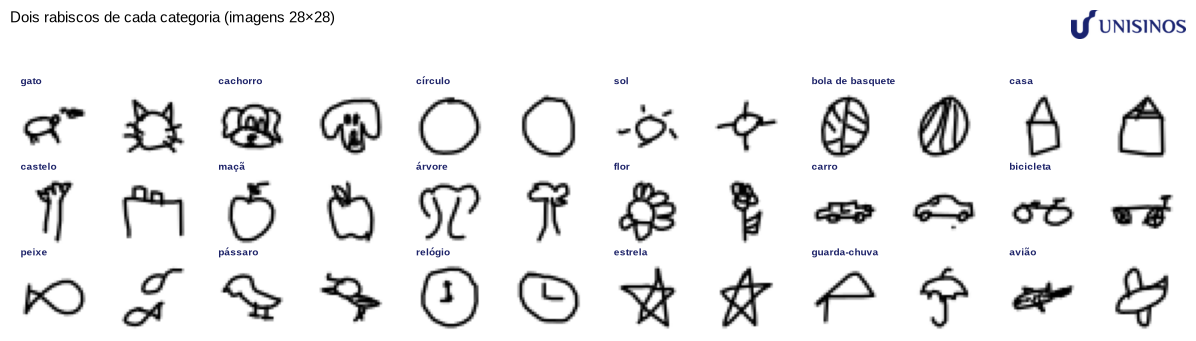

In [4]:
npz = Path(RAIZ) / 'dados' / 'quickdraw-subconjunto.npz'
if not npz.exists():
    import importlib.util          # o arquivo se chama baixar-dados.py (hífen), então é carregado pelo caminho
    esp = importlib.util.spec_from_file_location('baixar_dados', Path(AQUI) / 'baixar-dados.py')
    baixar_dados = importlib.util.module_from_spec(esp); esp.loader.exec_module(baixar_dados)
    baixar_dados.main()          # alguns minutos; grava dados/quickdraw-subconjunto.npz
D = q.carregar()
NOMES = [str(n) for n in D['nomes_pt']]; K = len(NOMES)
if RAPIDO:                       # subconjuntos pequenos para rodar em poucos minutos
    for s in ('treino', 'val', 'teste'):
        i = np.random.RandomState(0).permutation(len(D['y_' + s]))[:6000 if s == 'treino' else 3000]
        D['x_' + s], D['y_' + s] = D['x_' + s][i], D['y_' + s][i]
xv, yv, xt, yt = D['x_val'], D['y_val'], D['x_teste'], D['y_teste']
print('categorias:', ', '.join(NOMES))
print({s: len(D['y_' + s]) for s in ('treino', 'val', 'teste')})

fig, ax = plt.subplots(3, 12, figsize=(12, 3.4))
for c in range(K):
    r, col = divmod(c, 6)
    for j in range(2):
        a = ax[r, col * 2 + j]; a.axis('off')
        a.imshow(D['x_treino'][np.flatnonzero(D['y_treino'] == c)[j]].reshape(28, 28), cmap='gray_r')
        if j == 0: a.set_title(NOMES[c], fontsize=7, loc='left')
fig.suptitle('Dois rabiscos de cada categoria (imagens 28×28)', x=0.01, ha='left'); q.com_logo(plt.gcf()); plt.show()

Os rabiscos são rápidos e irregulares: cada pessoa desenha do seu jeito. Há categorias que se parecem de propósito (gato e cachorro, círculo, sol e bola, casa e castelo, pássaro e avião), o que torna o desafio mais interessante.

## 2. Pergunta 1: uma CNN reconhece melhor que um MLP e que uma conta simples?
Três "jogadores", do mais simples ao mais esperto:

- **Regressão logística** (linha de base): uma única conta com os 784 pixels, sem camadas escondidas.
- **MLP**: rede comum com duas camadas escondidas; recebe os pixels como uma lista e não sabe quem é vizinho de quem.
- **CNN** (rede convolucional): usa pequenos filtros 3×3 que deslizam pela imagem, procurando traços (cantos, curvas, linhas). Tem apenas 80 mil parâmetros.

Uma quarta versão, a **CNN + aumento de dados**, treina vendo desenhos levemente girados, deslocados e redimensionados. Os modelos são treinados com sementes fixas; a função `obter` reaproveita um modelo já treinado (pasta `modelos/_cache`), se existir.

In [5]:
EP = dict(baseline=15, mlp=12, cnn=5, cnn_aug=6) if not RAPIDO else dict(baseline=3, mlp=3, cnn=2, cnn_aug=2)
SEMENTES = ({'baseline': [0, 1, 2], 'mlp': [0, 1, 2], 'cnn': [0, 1, 2], 'cnn_aug': [0, 1]} if not RAPIDO else {k: [0] for k in EP})
CACHE = None if RAPIDO else Path(RAIZ) / 'modelos' / '_cache'      # no modo RAPIDO nada é reaproveitado
n_total = len(D['y_treino'])

def n_epocas(nome, n):
    ep = EP[nome]                                   # amostras pequenas recebem mais épocas (mínimo de passos)
    if n < n_total * 0.9 and not RAPIDO:
        ep = int(min(60, max(ep, np.ceil(1000 / np.ceil(n / 256)))))
    return ep

def obter(nome, semente, x, y, tag=''):
    """Treina (ou lê do cache) um modelo: nome em baseline, mlp, cnn, cnn_aug."""
    base, aug = ('cnn', True) if nome == 'cnn_aug' else (nome, False)
    arq = None if CACHE is None else CACHE / f'{nome}{tag}_s{semente}.pt'
    if arq is not None and arq.exists():
        z = torch.load(arq); m = q.MODELOS[base](); m.load_state_dict(z['w']); return m, z['hist'], z['seg']
    t0 = time.time()
    m, h = q.treinar(base, x, y, xv, yv, n_epocas(nome, len(y)), aug=aug, semente=semente, verbose=False)
    return m, h, time.time() - t0

t_ini = time.time()
lin, modelos, logs, hist = [], {}, {}, {}
for nome in EP:
    for s in SEMENTES[nome]:
        m, h, seg = obter(nome, s, D['x_treino'], D['y_treino'])
        lg = q.logits(m, xt); pred = lg.argmax(1).numpy()
        lo, hi = q.wilson((pred == yt).sum(), len(yt))
        lin.append(dict(modelo=nome, semente=s, parametros=q.n_parametros(m), acc=(pred == yt).mean().item(), top3=q.top_k(lg, yt, 3), lo=lo, hi=hi))
        modelos[(nome, s)], logs[(nome, s)], hist[(nome, s)] = m, lg, h
        print(f'{nome:9s} semente {s}: acurácia {lin[-1]["acc"]*100:5.1f}%  top-3 {lin[-1]["top3"]*100:5.1f}%')

baseline  semente 0: acurácia  69.0%  top-3  86.0%
baseline  semente 1: acurácia  69.0%  top-3  86.0%
baseline  semente 2: acurácia  69.0%  top-3  86.0%


mlp       semente 0: acurácia  85.1%  top-3  94.6%
mlp       semente 1: acurácia  84.9%  top-3  94.7%


mlp       semente 2: acurácia  84.8%  top-3  94.5%


cnn       semente 0: acurácia  89.9%  top-3  96.5%


cnn       semente 1: acurácia  89.9%  top-3  96.5%


cnn       semente 2: acurácia  90.6%  top-3  96.7%


cnn_aug   semente 0: acurácia  89.8%  top-3  96.5%


cnn_aug   semente 1: acurácia  89.9%  top-3  96.5%


modelo               parâmetros  acurácia          IC 95%   top-3
Regressão logística      14.130     69,0%  68,5–69,4%   86,0%
MLP                     236.178     84,9%  84,5–85,3%   94,6%
CNN                      80.434     90,2%  89,9–90,5%   96,6%
CNN + aumento            80.434     89,8%  89,5–90,1%   96,5%


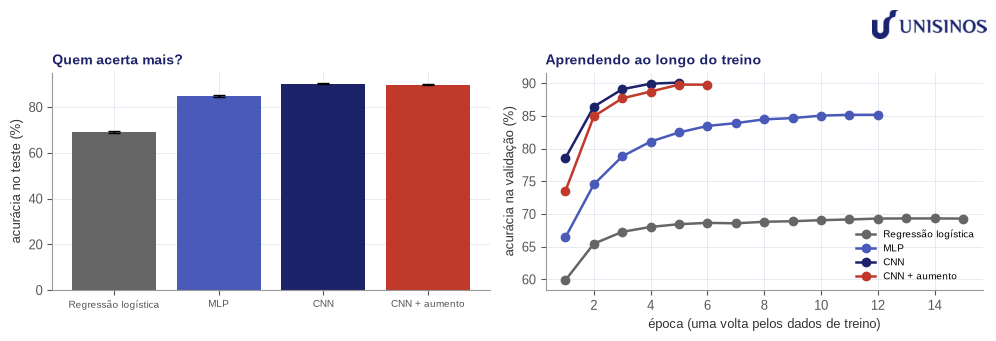

In [6]:
NOMEM = {'baseline': 'Regressão logística', 'mlp': 'MLP', 'cnn': 'CNN', 'cnn_aug': 'CNN + aumento'}
resumo_mod = []
for nome in EP:
    L = [r for r in lin if r['modelo'] == nome]; a = np.array([r['acc'] for r in L])
    lo, hi = q.wilson(a.mean() * len(yt), len(yt))
    resumo_mod.append(dict(modelo=nome, parametros=L[0]['parametros'], sementes=len(L), acc=a.mean(), lo=lo, hi=hi,
                           top3=np.mean([r['top3'] for r in L]), desvio=a.std(ddof=1) if len(a) > 1 else float('nan')))
print(f'{"modelo":20s}{"parâmetros":>11s}{"acurácia":>10s}{"IC 95%":>16s}{"top-3":>8s}')
for r in resumo_mod:
    npar = format(r['parametros'], ',').replace(',', '.')
    print(f'{NOMEM[r["modelo"]]:20s}{npar:>11s}{virg(r["acc"]*100):>9s}%  {virg(r["lo"]*100)}–{virg(r["hi"]*100)}%{virg(r["top3"]*100):>7s}%')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
cores = [COR['cinza'], COR['azul2'], COR['azul'], COR['vermelho']]
ax[0].bar([NOMEM[r['modelo']] for r in resumo_mod], [r['acc'] * 100 for r in resumo_mod], color=cores,
          yerr=[[(r['acc'] - r['lo']) * 100 for r in resumo_mod], [(r['hi'] - r['acc']) * 100 for r in resumo_mod]], capsize=4)
ax[0].set_ylabel('acurácia no teste (%)'); ax[0].set_title('Quem acerta mais?', loc='left'); ax[0].tick_params(axis='x', labelsize=7)
for nome, cor in zip(EP, cores):
    h = hist[(nome, SEMENTES[nome][0])]
    ax[1].plot([e['epoca'] for e in h], [e['acc_val'] * 100 for e in h], marker='o', color=cor, label=NOMEM[nome])
ax[1].set_xlabel('época (uma volta pelos dados de treino)'); ax[1].set_ylabel('acurácia na validação (%)'); ax[1].legend(fontsize=7)
ax[1].set_title('Aprendendo ao longo do treino', loc='left'); q.com_logo(plt.gcf()); plt.show()

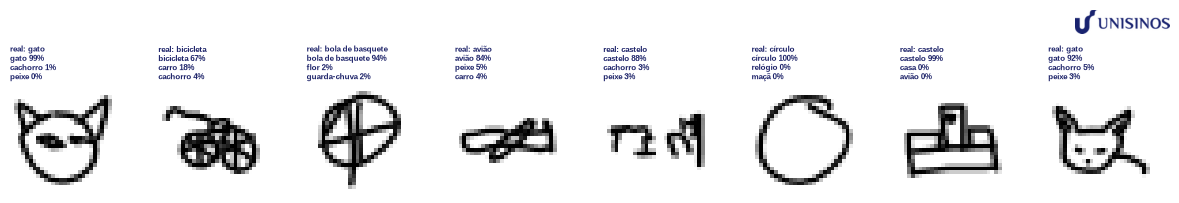

In [7]:
# Um palpite de verdade: 8 desenhos do teste, com o top-3 da CNN
mf0 = modelos[('cnn', 0)]; lg8 = torch.softmax(q.logits(mf0, xt[:8]), 1)
fig, ax = plt.subplots(1, 8, figsize=(12, 2.0))
for i in range(8):
    top = lg8[i].topk(3); real = NOMES[yt[i]]
    ax[i].imshow(xt[i].reshape(28, 28), cmap='gray_r'); ax[i].axis('off')
    ax[i].set_title(f'real: {real}\n' + '\n'.join(f'{NOMES[k]} {v*100:.0f}%' for v, k in zip(top.values, top.indices)), fontsize=6, loc='left')
q.com_logo(plt.gcf(), largura_pol=0.95, folga_topo=0.14); plt.show()   # folga maior: títulos de 3 linhas

**Interpretação.** A ordem esperada se confirma: a conta simples acerta cerca de dois terços dos desenhos, o MLP chega perto de 85% e a CNN passa de 90%, com **menos** parâmetros que o MLP. A explicação é intuitiva: o filtro da CNN procura o mesmo traço em qualquer parte da imagem e olha para vizinhos próximos, o que combina com desenhos. O intervalo de confiança (barras) mostra que a diferença entre os modelos é bem maior que o ruído de medição. A CNN com aumento de dados perde um pouco no teste padrão, mas, como se verá na seção 5, ganha em robustez.

## 3. Pergunta 2: que categorias a rede confunde, e por quê?
A **matriz de confusão** conta, para cada categoria real (linhas), o que a rede respondeu (colunas). O que fica fora da diagonal são os erros. Usa-se o modelo final do projeto: a CNN com aumento de dados (semente 0), escolhida porque perde no máximo 1 ponto para a CNN simples e é bem mais robusta.

modelo final: CNN + aumento
pares mais confundidos (trocas nos dois sentidos):
  gato e cachorro: 372 trocas (gato→cachorro: 239; cachorro→gato: 133; 9,3% das imagens do par)
  cachorro e pássaro: 197 trocas (cachorro→pássaro: 91; pássaro→cachorro: 106; 4,9% das imagens do par)
  pássaro e avião: 189 trocas (pássaro→avião: 151; avião→pássaro: 38; 4,7% das imagens do par)
  árvore e flor: 110 trocas (árvore→flor: 57; flor→árvore: 53; 2,8% das imagens do par)
  estrela e avião: 109 trocas (estrela→avião: 42; avião→estrela: 67; 2,7% das imagens do par)
mais difíceis: pássaro (70,6%), cachorro (75,2%), gato (77,7%)
mais fáceis: casa (96,7%), castelo (96,3%), bicicleta (95,9%)


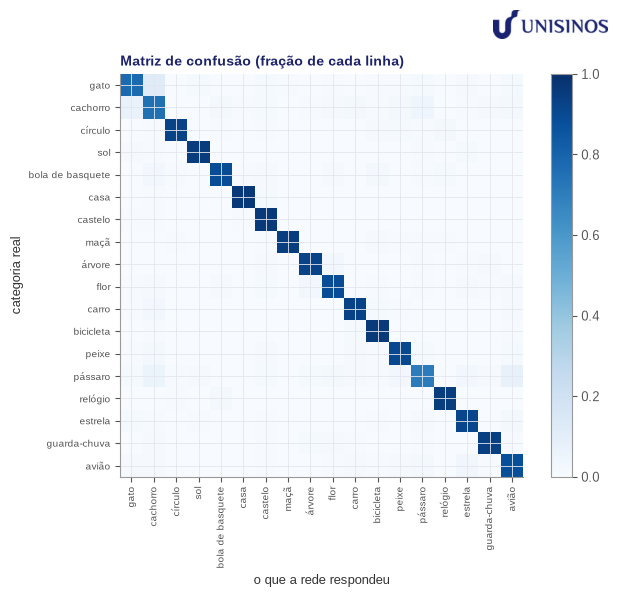

In [8]:
acc = {r['modelo']: r['acc'] for r in resumo_mod}
final = 'cnn_aug' if acc['cnn_aug'] >= acc['cnn'] - 0.01 else 'cnn'
mf, lgf = modelos[(final, 0)], logs[(final, 0)]
predf = lgf.argmax(1).numpy(); M = q.matriz_confusao(predf, yt, K)
conf = torch.softmax(lgf, 1).max(1).values.numpy()
print('modelo final:', NOMEM[final])
pares = []
for i in range(K):
    for j in range(i + 1, K):
        pares.append((NOMES[i], NOMES[j], int(M[i, j]), int(M[j, i]), (M[i, j] + M[j, i]) / (M[i].sum() + M[j].sum()) * 100))
pares.sort(key=lambda p: -(p[2] + p[3]))
print('pares mais confundidos (trocas nos dois sentidos):')
for a, b, ab, ba, pc in pares[:5]:
    print(f'  {a} e {b}: {ab + ba} trocas ({a}→{b}: {ab}; {b}→{a}: {ba}; {virg(pc)}% das imagens do par)')
por_classe = M.diagonal() / M.sum(1)
o = np.argsort(por_classe)
print('mais difíceis:', ', '.join(f'{NOMES[i]} ({virg(round(por_classe[i], 4)*100)}%)' for i in o[:3]))
print('mais fáceis:', ', '.join(f'{NOMES[i]} ({virg(round(por_classe[i], 4)*100)}%)' for i in o[::-1][:3]))

Mn = M / M.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(Mn, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels(NOMES, rotation=90, fontsize=7); ax.set_yticklabels(NOMES, fontsize=7)
ax.set_xlabel('o que a rede respondeu'); ax.set_ylabel('categoria real'); ax.set_title('Matriz de confusão (fração de cada linha)', loc='left')
plt.colorbar(im, fraction=0.04); q.com_logo(plt.gcf()); plt.show()

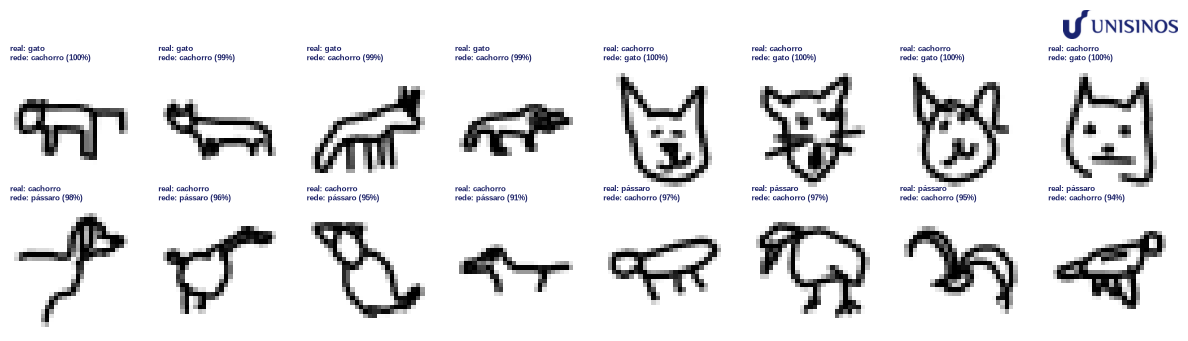

In [9]:
# Exemplos de erros dos dois pares mais confundidos (os mais "confiantes")
fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for r, (a, b, *_ ) in enumerate(pares[:2]):
    i, j = NOMES.index(a), NOMES.index(b); k = 0
    for real, pr in ((i, j), (j, i)):
        idx = np.flatnonzero((yt == real) & (predf == pr)); idx = idx[np.argsort(-conf[idx])][:4]
        for n in idx:
            ax[r, k].imshow(xt[n].reshape(28, 28), cmap='gray_r'); ax[r, k].axis('off')
            ax[r, k].set_title(f'real: {NOMES[real]}\nrede: {NOMES[pr]} ({conf[n]*100:.0f}%)', fontsize=6, loc='left'); k += 1
q.com_logo(plt.gcf()); plt.show()

**Interpretação.** As trocas acontecem entre desenhos que **de fato se parecem em 28×28**: gato e cachorro (quatro patas, focinho e orelhas pontudas), cachorro e pássaro, pássaro e avião (silhueta com asas). Alguns erros mostrados são rabiscos de corpo inteiro que enganariam até uma pessoa; outros são rostos de gato bem reconhecíveis que a rede errou com confiança altíssima, o que mostra que ela também falha "sem perceber". Já casa e castelo, com formas bem marcadas, estão entre as categorias mais fáceis. Boa parte do erro vem da ambiguidade do rabisco.

## 4. Pergunta 3: quantos desenhos de treino são necessários?
Os três modelos são treinados com 100, 500, 2.000 e 5.000 desenhos **por categoria** (mais o conjunto completo, de 8.000) e testados nos mesmos desenhos de teste. Amostras pequenas usam mais épocas, para que o modelo dê um número mínimo de passos de aprendizado.

Regressão logística  100: 59,7%  500: 64,5%  2000: 67,0%  5000: 68,3%  8000: 69,0%
MLP                  100: 60,7%  500: 72,8%  2000: 79,5%  5000: 83,6%  8000: 85,1%
CNN                  100: 75,9%  500: 84,6%  2000: 86,5%  5000: 88,5%  8000: 89,9%


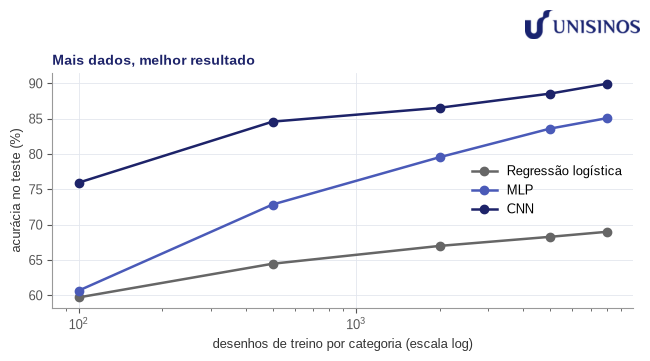

In [10]:
TAM = [100, 500, 2000, 5000] if not RAPIDO else [50, 200]
n_full = n_total // K
curva = {nome: {} for nome in ('baseline', 'mlp', 'cnn')}
for nome in curva:
    for n in TAM:
        x, y = q.subamostra(D['x_treino'], D['y_treino'], n, 0)
        m, h, seg = obter(nome, 0, x, y, tag=f'_n{n}')
        curva[nome][n] = q.acuracia(m, xt, yt)
    curva[nome][n_full] = [r['acc'] for r in lin if r['modelo'] == nome and r['semente'] == 0][0]
for nome, d in curva.items():
    print(f'{NOMEM[nome]:20s}', '  '.join(f'{n}: {virg(v*100)}%' for n, v in d.items()))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for nome, cor in zip(curva, (COR['cinza'], COR['azul2'], COR['azul'])):
    ax.plot(list(curva[nome]), [v * 100 for v in curva[nome].values()], marker='o', color=cor, label=NOMEM[nome])
ax.set_xscale('log'); ax.set_xlabel('desenhos de treino por categoria (escala log)'); ax.set_ylabel('acurácia no teste (%)')
ax.set_title('Mais dados, melhor resultado', loc='left'); ax.legend(); q.com_logo(plt.gcf()); plt.show()

**Interpretação.** A CNN já é boa com poucos exemplos: com 500 desenhos por categoria alcança cerca de 94% do resultado final (no modo completo). O MLP precisa de bem mais dados e ainda estava subindo no fim. As curvas da CNN e do MLP não dão sinal claro de parar de melhorar até 8.000 por categoria (a da regressão logística quase estabiliza), então mais dados talvez ajudassem os dois.

## 5. Pergunta 4: a rede lida com desenhos fora do padrão?
Os desenhos de teste (10.000 sorteados) são **deslocados, girados, encolhidos ou engrossados**, e mede-se a acurácia de três modelos: MLP, CNN e CNN com aumento de dados. O aumento de dados incluiu rotação até 15°, escala de 0,85 a 1,15 e deslocamento de 3 pixels, mas **não** incluiu espessura do traço.

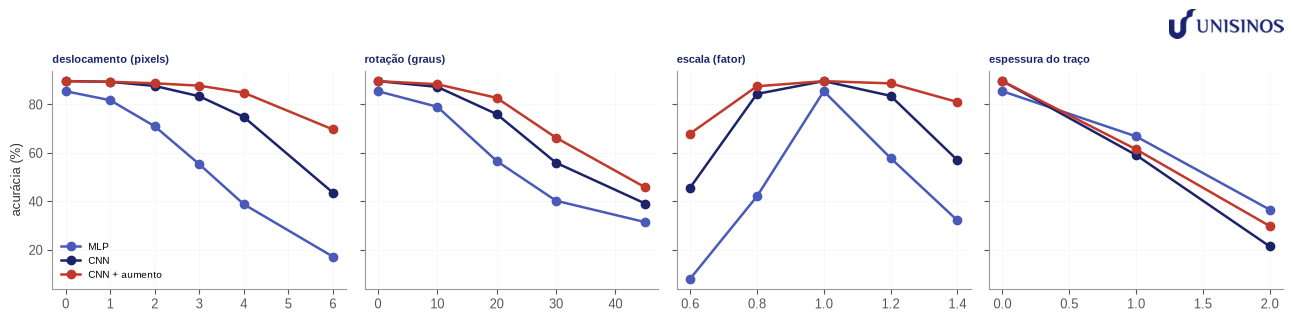

deslocamento (pixels) = 4: MLP 38,8%; CNN 74,8%; CNN + aumento 84,8%
rotação (graus) = 20: MLP 56,7%; CNN 76,0%; CNN + aumento 82,7%
escala (fator) = 0,6: MLP 8,1%; CNN 45,7%; CNN + aumento 68,0%
espessura do traço = 2: MLP 36,6%; CNN 21,4%; CNN + aumento 29,8%


In [11]:
sub = np.random.RandomState(1).permutation(len(yt))[:10000]; xr, yr = xt[sub], yt[sub]
GRADE = ([('deslocamento (pixels)', s, lambda x, s=s: q.afim(x, dx=float(s))) for s in (0, 1, 2, 3, 4, 6)] +
         [('rotação (graus)', a, lambda x, a=a: q.afim(x, angulo=float(a))) for a in (0, 10, 20, 30, 45)] +
         [('escala (fator)', e, lambda x, e=e: q.afim(x, escala=float(e))) for e in (0.6, 0.8, 1.0, 1.2, 1.4)] +
         [('espessura do traço', n, lambda x, n=n: q.espessura(x, n)) for n in (0, 1, 2)])
rob = {nome: [(t, v, q.acuracia(modelos[(nome, 0)], xr, yr, f)) for t, v, f in GRADE] for nome in ('mlp', 'cnn', 'cnn_aug')}
tipos = list(dict.fromkeys(t for t, _, _ in GRADE))
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for a, t in zip(ax, tipos):
    for nome, cor in (('mlp', COR['azul2']), ('cnn', COR['azul']), ('cnn_aug', COR['vermelho'])):
        pts = [(v, acc * 100) for tt, v, acc in rob[nome] if tt == t]
        a.plot(*zip(*pts), marker='o', color=cor, label=NOMEM[nome])
    a.set_title(t, fontsize=8, loc='left'); a.grid(alpha=.3)
ax[0].set_ylabel('acurácia (%)'); ax[0].legend(fontsize=7); q.com_logo(plt.gcf()); plt.show()
for t, v in (('deslocamento (pixels)', 4), ('rotação (graus)', 20), ('escala (fator)', 0.6), ('espessura do traço', 2)):
    print(f'{t} = {virg(v, 1) if isinstance(v, float) else v}: ' + '; '.join(f'{NOMEM[n]} {virg(round([a for tt, vv, a in rob[n] if tt == t and vv == v][0], 4)*100)}%' for n in rob))

**Interpretação.** O MLP desaba com qualquer mudança de posição ou tamanho, porque aprendeu "o pixel tal está aceso" e não "há uma curva aqui". A CNN aguenta bem mais, e a CNN com aumento de dados aguenta ainda mais, justamente porque viu esses tipos de variação no treino. A exceção é o **traço grosso**: como o aumento não incluía espessura, ele não ajudou, e o MLP chegou a ir melhor que a CNN. Lição: o aumento de dados só protege contra o tipo de variação que foi apresentado. Observação: o teste com traço mais fino (erosão) foi descartado, pois apaga o desenho e leva qualquer modelo ao acaso (cerca de 6%).

## 6. Pergunta 5: a confiança da rede é confiável?
A rede responde com uma probabilidade ("tenho 90% de certeza"). Ela é **calibrada** se, entre os palpites com 90% de confiança, cerca de 90% estiverem certos. O **ECE** resume a distância entre confiança e acerto (quanto menor, melhor). Também se testa o **ajuste de temperatura**, que suaviza ou afia as probabilidades sem mudar as respostas, usando só os dados de validação.

CNN            ECE 0,56%  | com temperatura T=1,02: ECE 0,72%


CNN + aumento  ECE 2,11%  | com temperatura T=1,28: ECE 0,83%
confiança média quando acerta: 95,3%; quando erra: 61,6%


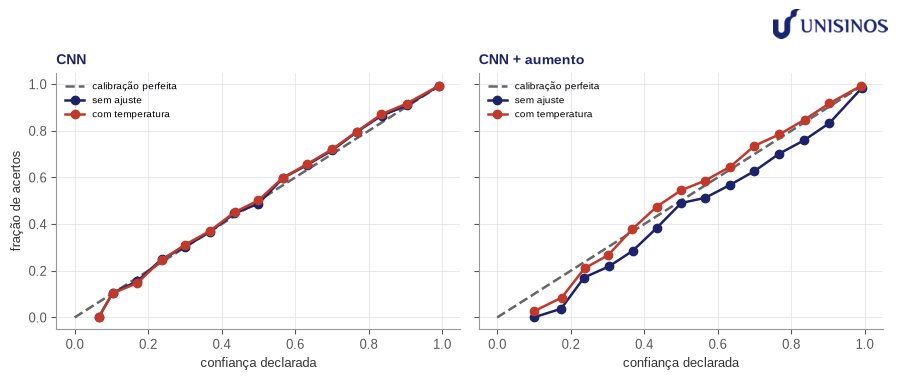

In [12]:
cal = {}
for nome in ('cnn', 'cnn_aug'):
    lt = logs[(nome, 0)]; T = q.ajustar_temperatura(q.logits(modelos[(nome, 0)], xv), yv)
    e0, p0 = q.ece(torch.softmax(lt, 1), yt); e1, p1 = q.ece(torch.softmax(lt / T, 1), yt)
    cal[nome] = dict(ece=e0, ece_T=e1, T=T, pts=p0, pts_T=p1)
    print(f'{NOMEM[nome]:14s} ECE {virg(e0*100, 2)}%  | com temperatura T={virg(T, 2)}: ECE {virg(e1*100, 2)}%')
ok = predf == yt
print(f'confiança média quando acerta: {virg(conf[ok].mean()*100)}%; quando erra: {virg(conf[~ok].mean()*100)}%')
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for a, nome in zip(ax, ('cnn', 'cnn_aug')):
    a.plot([0, 1], [0, 1], '--', color=COR['cinza'], label='calibração perfeita')
    for pts, cor, rot in ((cal[nome]['pts'], COR['azul'], 'sem ajuste'), (cal[nome]['pts_T'], COR['vermelho'], 'com temperatura')):
        a.plot([p[0] for p in pts], [p[1] for p in pts], marker='o', color=cor, label=rot)
    a.set_title(NOMEM[nome], loc='left'); a.set_xlabel('confiança declarada'); a.legend(fontsize=7)
ax[0].set_ylabel('fração de acertos'); q.com_logo(plt.gcf()); plt.show()

**Interpretação.** A CNN simples já é **bem calibrada sem nenhum ajuste** (ECE próximo de 0,6%): quando diz 90%, acerta cerca de 90%. A CNN com aumento fica um pouco "confiante demais" (ECE de 2,1%), e a temperatura corrige quase tudo (para 0,8%). Na prática, a confiança serve de alarme: média de cerca de 95% quando a rede acerta e de cerca de 62% quando erra, então um palpite com confiança baixa merece segunda olhada.

## 7. Conclusões e conferência com o relatório
1. A CNN pequena (80 mil parâmetros) supera o MLP e a regressão logística, com menos parâmetros que o MLP.
2. Os erros concentram-se em categorias de silhueta parecida (gato e cachorro à frente).
3. Cerca de 500 desenhos por categoria já rendem a maior parte do desempenho da CNN; mais dados continuam ajudando.
4. O aumento de dados torna a rede muito mais robusta a deslocamento, rotação e escala, mas não a traço grosso, que não foi treinado.
5. A confiança da rede é confiável, e a temperatura ajuda quando o treino usa aumento de dados.

**Limites.** As imagens são de 28×28 e simplificadas; o rabisco feito por uma pessoa em tela de toque difere da distribuição do treino. As categorias são só 18.

A célula abaixo compara os números calculados aqui com os de `resultados/resumo.json` (relatório). No modo completo, a conferência é obrigatória; no modo RAPIDO, os números **são diferentes** (e isso é esperado), pois vêm de menos dados e menos épocas.

In [13]:
import json
arq_res = Path(RAIZ) / 'resultados' / 'resumo.json'
if RAPIDO:
    print('Modo RAPIDO: os números acima NÃO são os do relatório. Os valores do relatório vêm do treino completo em resultados/.')
elif arq_res.exists():
    R = json.load(open(arq_res, encoding='utf-8')); lista = []
    for r in R['comparacao']:
        mm = [x for x in resumo_mod if x['modelo'] == r['modelo']][0]
        lista += [(f'acurácia {r["modelo"]}', mm['acc'], r['acc_media']), (f'top-3 {r["modelo"]}', mm['top3'], r['top3_media'])]
    for nome in ('baseline', 'mlp', 'cnn'):
        for n, v in R['curva_aprendizado'][nome].items(): lista.append((f'curva {nome} {n}', curva[nome][int(n)], v))
    lista += [('ECE cnn', cal['cnn']['ece'], R['calibracao']['cnn']['ece']), ('ECE cnn_aug', cal['cnn_aug']['ece'], R['calibracao']['cnn_aug']['ece']),
              ('ECE cnn_aug com T', cal['cnn_aug']['ece_T'], R['calibracao']['cnn_aug']['ece_depois_temperatura'])]
    pm = R['par_mais_confundido']; lista.append(('par gato/cachorro (trocas)', pares[0][2] + pares[0][3], pm['total']))
    pior = max(abs(a - b) for _, a, b in lista)
    print(f'{len(lista)} números conferidos; maior diferença: {pior:.5f}')
    assert pior < 6e-4, 'números diferem do relatório'
    print('OK: os números do notebook batem com resultados/resumo.json')
else:
    print('resultados/resumo.json não encontrado; conferência pulada.')
print(f'tempo total do notebook: {(time.time() - t_ini) / 60:.1f} min')

27 números conferidos; maior diferença: 0.00008
OK: os números do notebook batem com resultados/resumo.json
tempo total do notebook: 3.8 min
